# Behavior analyses on rollouts vs real fish


## Stimulus-programme rollout tool

This section generates simulated fish trajectories from a trained model, given a stimulus trajectory file.  
The generated rollouts are then compared to real fish trajectories using similar analyses on fish behavior.  
Code to generate rollouts is taken from `stimulus_tool.ipynb`.

**Inputs :**

 - stimulus trajectory file : `assets/stimulus/2025.02.20-0957_trajectory_GsizeMotionSingle_180min.csv.gz` 
 - trained model : `assets/models/ladder_b_indiv.pt` 
 
 Choosing rollout parameters : 

 - MODEL_KEY : J10 is current best model, it is the only one in the current keys available for the repo.
 - N_ROLLOUTS : number of rollouts to generate, 3 as a minimum is recommended to be able to generate the mp4 file correctly (video shows first 3 rollouts)
 - WINDOWS : set `WINDOWS = [(lo, hi, 'label'), (lo2, hi2, 'label2')]` in frames.
 - VIDEO_SPEED : speed of mp4 video render, 3.0 is default.

In [2]:
%load_ext autoreload
%autoreload 2

import sys, time, json, re
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / 'scripts').exists() and (ROOT.parent / 'scripts').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'scripts'))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
if not hasattr(np, '_core'):                 # load Colab (numpy 2) checkpoints under numpy 1
    import numpy.core as _nc; np._core = _nc

import evaluate as E, fit_MLP_border as MB, fit_MLP_mix as MX
import stim_program as SP, stim_rollout as SR, tool_video as TV, tool_reference as TR
from gen_frame_long import build_gen_fish_df_long
from real_frame_long import build_fish_df_long


In [5]:
def pick(*candidates):
    """First path that exists, else None. Everything the tool reads is resolved this way:
    the full local dataset when you have it, the small shipped assets/ copy otherwise."""
    for c in candidates:
        p = ROOT / c
        if p.exists():
            return p
    return None
NETWORK_PATH = Path('/Volumes/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/07_Data/Matilde/Behavior')
# '20250220_MP_01_GsizeMotionSingle/2025.02.20-0957_trajectory_GsizeMotionSingle_180min.csv'
# '20250316_MP_01_GsizeMotionSingle/2025.03.16-1203_trajectory_GsizeMotionSingle_360min.csv'
TRAJ_FILE =   pick(NETWORK_PATH / '20250220_MP_01_GsizeMotionSingle/2025.02.20-0957_trajectory_GsizeMotionSingle_180min.csv') 
ROI_FILE  = pick('assets/ROIdef2025-02-20T12_09_16.csv')
BOUTS     = None      # None in a clean clone
REFERENCE = pick('assets/real_reference.npz')
DATA_DIR  = pick('data/20250220_MP_01_GsizeMotionSingle/')   # full-res real tracking, if present
HAS_REAL_DATA = DATA_DIR is not None   # False when analysing a stimulus programme with no matching real dataset

# Params
MODEL_KEY  = 'J10'
N_ROLLOUTS = 15              # matches the real fish count (15) for comparable SEM/error bars
SEED       = 0
WINDOWS    = None           # None = auto-pick two contrasting blocks
VIDEO_SPEED = 3.0           # 3x real time
OUT_DIR = ROOT / 'tool_videos'
SPEED_THRESH_K = 1.0        # real-data bout-detection threshold (segment_bouts.segment_fish)
PX_TO_MM = 3.67

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'savefig.facecolor': 'white', 'figure.dpi': 110})
REAL, GEN = '#3C3C3C', '#1F3B8C'
print('ROOT     ', ROOT)
print('python   ', sys.version.split()[0], '| numpy', np.__version__)
print('stimulus ', TRAJ_FILE.name if TRAJ_FILE else 'MISSING')
print('roi      ', ROI_FILE.name if ROI_FILE else 'MISSING')
print('reference', 'bouts CSV (full local data)' if BOUTS else
                   (REFERENCE.name if REFERENCE else 'MISSING'))
print('real data', DATA_DIR if HAS_REAL_DATA else 'not found -- real-vs-generated comparisons will be skipped')
assert TRAJ_FILE and ROI_FILE and (BOUTS or REFERENCE), 'missing inputs -- see the README'


ROOT      /Users/matilde/code/digital_twin
python    3.13.5 | numpy 2.4.3
stimulus  2025.02.20-0957_trajectory_GsizeMotionSingle_180min.csv
roi       ROIdef2025-02-20T12_09_16.csv
reference real_reference.npz
real data /Users/matilde/code/digital_twin/data/20250220_MP_01_GsizeMotionSingle


In [6]:
# key -> candidate paths, first existing wins. Only J10 ships with the repo
MODELS = {
    'J10':           ['assets/models/ladder_b_indiv.pt',        # the thesis J10 (traj AUC 0.704)
                      'notebooks/_zip_full/ladder_b_indiv.pt'],
    'J10_150ep':     ['ladder_b_indiv150.pt'],                  # same recipe, 150 epochs
    'J10_cal2q':     ['ladder_b_indiv150_cal2q.pt'],            # recalibrated containment
    'J10_psi_basis': ['ladder_b_indiv_psib_cal2q.pt'],          # J10 + psi-frame + border basis
    'J17':           ['ladder_re_swap_gr.pt'],                  # fitted per-fish latent, m=2
}
_p = pick(*MODELS[MODEL_KEY])
if _p is None:
    raise FileNotFoundError(
        f"{MODEL_KEY} not found. Tried: {MODELS[MODEL_KEY]}. "
        f"Only 'J10' ships with the repo; the others need the full research checkout.")
model = MX.load_mix(str(_p))
cf = model._cfg_feat

records = MB.build_border_records(E.load_bouts(str(BOUTS)), roi_path=str(ROI_FILE)) if BOUTS else None
ref = TR.reference_from_records(records) if records else TR.load_reference(REFERENCE)


In [7]:
# Raw (untrimmed) trajectory exports can start with a 'start_none' habituation period -- the dish
# idle before the pause/stimulus loop proper begins -- sometimes followed by a mid-file 'bout'
# calibration block before the assay's own first pause. Neither is a real stimulus label
# (segment_bouts.STIM_NONE doesn't include 'start_none', so SP.load_program's active/size
# cross-check flags it as malformed) and AllFish_GsizeMotionSingle.ipynb already treats this
# region as pre-assay filler. If present, trim it here (inline -- not inside stim_program.py)
# before parsing: keep only the final contiguous 'none' pause immediately before the first real
# (CLsemi) block, exactly what the shipped assets/ copy (already trimmed this way) starts from.
import tempfile

def _trim_habituation(path, fps=SP.FPS):
    first = pd.read_csv(path, header=None, nrows=1)
    if str(first.iloc[0, 0]) != 'start_none':
        return path   # already trimmed (or was never exported with a habituation period)
    raw = pd.read_csv(path, header=None)
    name0 = raw[0].astype(str).to_numpy()
    is_stim_row = np.array([isinstance(v, str) and v.startswith('CLsemi') for v in name0])
    if not is_stim_row.any():
        return path
    j = int(np.argmax(is_stim_row))
    while j > 0 and name0[j - 1] == 'none':
        j -= 1
    print(f'{path}: dropping {j} leading pre-assay frames (start_none/bout before the '
         f'first stimulus block, {j / fps:.1f}s)')
    out_path = Path(tempfile.gettempdir()) / f'trimmed_{Path(path).name}'
    raw.iloc[j:].to_csv(out_path, header=False, index=False)
    return out_path

# Load stim program file
program = SP.load_program(_trim_habituation(TRAJ_FILE))
print(program.summary())

# Show the first 10 rows of the block table
program.block_table().head(10)

2025.02.20-0957_trajectory_GsizeMotionSingle_180min.csv: 315000 frames (175.0 min @ 30 fps), 8 dot slots
  191 blocks -> 95 stimulus / 96 pause
  16 conditions; N in [1, 2, 4, 6, 8]; moving 60 / static 35


,block,label,start_frame,end_frame,dur_s,n_dots,moving,side,is_stim
0,0,none,0,1500,50.0,0.0,False,none,False
1,1,CLsemi1800_g4-0_s3.5-3.5,1500,3300,60.0,4.0,True,left,True
2,2,none,3300,4800,50.0,0.0,False,none,False
3,3,CLsemi1800_g0-2_s3.5-3.5,4800,6600,60.0,2.0,True,right,True
4,4,none,6600,8100,50.0,0.0,False,none,False
5,5,CLsemi1800_g0-4_s3.5-3.5,8100,9900,60.0,4.0,True,right,True
6,6,none,9900,11400,50.0,0.0,False,none,False
7,7,CLsemi1800_g8-0_s3.5-3.5,11400,13200,60.0,8.0,True,left,True
8,8,none,13200,14700,50.0,0.0,False,none,False
9,9,CLsemi1800_g0-4_s0-0,14700,16500,60.0,4.0,False,right,True


In [8]:
# NGenerate rollouts
dish = SR.default_dish(roi_path=str(ROI_FILE))

t0 = time.time()
rollouts = SR.rollout_many(model, program, N_ROLLOUTS, seed=SEED,
                           dish=dish, pose_sampler=ref.sample_start_pose)
print(f'{N_ROLLOUTS} rollouts in {time.time() - t0:.1f}s')


  rollout 0: 4604 bouts, last onset 174.94 of 175.00 min (short by 3.4s), median dt 1.52s, max r/R 0.998, 0.6s
  rollout 1: 5356 bouts, last onset 174.99 of 175.00 min (short by 0.6s), median dt 1.33s, max r/R 0.993, 0.7s
  rollout 2: 5597 bouts, last onset 175.00 of 175.00 min (short by 0.2s), median dt 1.33s, max r/R 0.997, 0.8s
  rollout 3: 4840 bouts, last onset 174.99 of 175.00 min (short by 0.6s), median dt 1.61s, max r/R 0.994, 0.7s
  rollout 4: 4326 bouts, last onset 174.97 of 175.00 min (short by 1.5s), median dt 1.70s, max r/R 0.999, 0.6s
  rollout 5: 5715 bouts, last onset 174.26 of 175.00 min (short by 44.6s), median dt 1.28s, max r/R 0.997, 0.8s
  rollout 6: 6286 bouts, last onset 174.85 of 175.00 min (short by 8.9s), median dt 1.14s, max r/R 0.978, 0.9s
  rollout 7: 4983 bouts, last onset 174.65 of 175.00 min (short by 21.2s), median dt 1.55s, max r/R 0.997, 0.8s
  rollout 8: 6624 bouts, last onset 175.00 of 175.00 min (short by 0.1s), median dt 1.12s, max r/R 1.000, 0.9s

## Frame-based analyses, real and generated

Rebuilds `fish_df_long` (frame-based, egocentric/rotated real-fish trajectories) from `DATA_DIR`.  Also builds `gen_fish_df_long`, the same shape for the generated `rollouts`.

Rollouts are bout-native (the model predicts an instantaneous jump per bout; nothing is simulated in between), so `scripts/gen_frame_long.py` synthesizes a 30fps trajectory via "dart-and-hold" (the same bout->frame reconstruction already used for rollout comparison videos) before running it through the identical rotate/melt/distance pipeline for generating `fish_df_long`.  

The resulting `gen_fish_df_long` is then used for the same analyses as `fish_df_long`, including occupancy maps, bout distributions, and bout transition matrices.

In [11]:
framerate = 30  # fps
if HAS_REAL_DATA:
    fish_df_long, meta = build_fish_df_long(DATA_DIR, ROI_FILE)
    experiment, n_fish, n_stimuli = meta['experiment'], meta['n_fish'], meta['n_stimuli']
    print(f"{n_fish} fish, {n_stimuli} dots, experiment={experiment!r}, fish_df_long: {fish_df_long.shape}")
else:
    fish_df_long, n_fish = None, None
    print('no real data (DATA_DIR is None) -- frame-based analyses below are skipped')
fish_df_long.head() if fish_df_long is not None else None

15 fish, 8 dots, experiment='GsizeMotionSingle', fish_df_long: (4702500, 34)


,fish_number,frame,trial_id,condition,stimulus_block_id,frame_count_stimulus,trial_start,ori,theta_rot,x,...,dotsDist,dotsDist_ego,dotsDist_rot,squareDist_rot,stim_side,stimulus,first_choice,condition_grouped,speed,scaled_speed
0,0,0,1,inter_stim_pause,1,0,True,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,R,inter_stim_pause,right,inter_stim_pause,NaN,NaN
1,0,1,1,inter_stim_pause,1,1,False,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,R,inter_stim_pause,<NA>,inter_stim_pause,NaN,NaN
2,0,2,1,inter_stim_pause,1,2,False,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,R,inter_stim_pause,<NA>,inter_stim_pause,NaN,NaN
3,0,3,1,inter_stim_pause,1,3,False,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,R,inter_stim_pause,<NA>,inter_stim_pause,NaN,NaN
4,0,4,1,inter_stim_pause,1,4,False,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,R,inter_stim_pause,<NA>,inter_stim_pause,NaN,NaN


In [12]:
# Transform the generated rollouts into a frame-based, egocentric/rotated long-form DataFrame, like fish_df_long.  
gen_fish_df_long, gen_meta = build_gen_fish_df_long(rollouts, program)
n_rollouts_frame = gen_meta['n_fish']
print(f"{n_rollouts_frame} rollouts, gen_fish_df_long: {gen_fish_df_long.shape}")

  rollout 0: synthesized, held for the final 3.4s (ran out of bouts before the programme ended)
  rollout 1: synthesized, held for the final 0.6s (ran out of bouts before the programme ended)
  rollout 2: synthesized, held for the final 0.2s (ran out of bouts before the programme ended)
  rollout 3: synthesized, held for the final 0.6s (ran out of bouts before the programme ended)
  rollout 4: synthesized, held for the final 1.5s (ran out of bouts before the programme ended)
  rollout 5: synthesized, held for the final 44.6s (ran out of bouts before the programme ended)
  rollout 6: synthesized, held for the final 8.9s (ran out of bouts before the programme ended)
  rollout 7: synthesized, held for the final 21.2s (ran out of bouts before the programme ended)
  rollout 8: synthesized, held for the final 0.1s (ran out of bouts before the programme ended)
  rollout 9: synthesized, held for the final 0.3s (ran out of bouts before the programme ended)
  rollout 10: synthesized, held for th

In [10]:
# ---- Plot config: shared sizing/styling + stimulus labels & colors ----
# Font/line/marker sizes scaled down by the same ~0.68 factor as CELL_W/H's 2.2 -> 1.5 shrink,
# so panels get smaller without text/markers looking oversized relative to them.
FS_SUP, FS_TITLE, FS_LABEL, FS_TICK = 11, 6, 4, 6     # suptitle/title/axis-label/tick font sizes
LW = 0.9                                             # line width for mean+-SEM traces
FIG_SINGLE = (4.8, 3)                                # figsize for a standalone single-panel plot
CELL_W, CELL_H = 1.8, 1.8                            # inches per subplot in small-multiple grids
DOT_FRAME = dict(s=.3, alpha=.06, edgecolor='none')    # scatter style: frame-level (~1e6 pts)

# One subfolder per trajectory file (named after its parent folder, e.g. the experiment's data
# folder), so plots from different stimulus programmes/experiments never overwrite each other.
PLOTS_DIR = ROOT / 'plots' / TRAJ_FILE.parent.name
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
print('saving plots to', PLOTS_DIR)

MOTION_CMAP, STATIC_CMAP = 'RdPu', 'Oranges'
COND_COLORS = {'Real': {'motion': 'darkcyan', 'static': 'darkgrey'},
              'Generated': {'motion': 'darkmagenta', 'static': 'plum'}}

# set color for real vs generated scatter plots
COLORS = {'Real': 'darkcyan', 'Generated': 'darkmagenta'}

def parse_stim(stim):
    """'d1s3.5' -> (1, 3.5). (None, None) for non-matching strings."""
    m = re.match(r"d(\d+)s([\d.]+)$", stim)
    return (int(m.group(1)), float(m.group(2))) if m else (None, None)

def is_motion(stim):
    d, s = parse_stim(stim)
    return d is not None and s not in (None, 0.0)

def is_static(stim):
    d, s = parse_stim(stim)
    return d is not None and s == 0.0

def auto_label(stim):
    if stim == 'inter_stim_pause':
        return 'control'
    d, s = parse_stim(stim)
    return f"{d} - {'static' if s == 0 else 'motion'}" if d is not None else stim

def dots_label(stim):
    return 'control' if stim == 'inter_stim_pause' else str(parse_stim(stim)[0])

# Stimulus order and color maps: ordered by (static/motion, dot count, speed), one color per dot count
_seen_stimuli = set(gen_fish_df_long['stimulus']) - {'inter_stim_pause'}
STIMULI_ORDER = sorted(_seen_stimuli, key=lambda s: (is_static(s),) + parse_stim(s))
STIM_35 = [s for s in STIMULI_ORDER if is_motion(s)]   # name kept for compat; = the motion stimuli
STIM_0  = [s for s in STIMULI_ORDER if is_static(s)]   # = the static stimuli

motion_dots_sorted = sorted({parse_stim(s)[0] for s in STIM_35})
static_dots_sorted = sorted({parse_stim(s)[0] for s in STIM_0})
dot_to_motion_color = dict(zip(motion_dots_sorted, sns.color_palette(MOTION_CMAP, len(motion_dots_sorted))))
dot_to_static_color = dict(zip(static_dots_sorted, sns.color_palette(STATIC_CMAP, len(static_dots_sorted))))

color_map = {s: dot_to_motion_color[parse_stim(s)[0]] for s in STIM_35}
color_map.update({s: dot_to_static_color[parse_stim(s)[0]] for s in STIM_0})
color_map['inter_stim_pause'] = 'gray'

saving plots to /Users/matilde/code/digital_twin/plots/20250220_MP_01_GsizeMotionSingle


#### 1. Occupancy maps

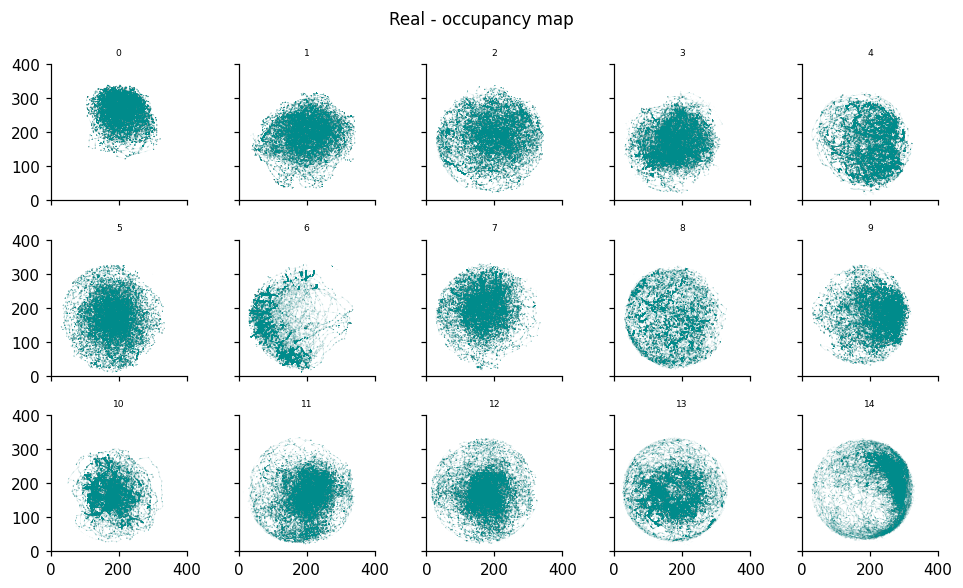

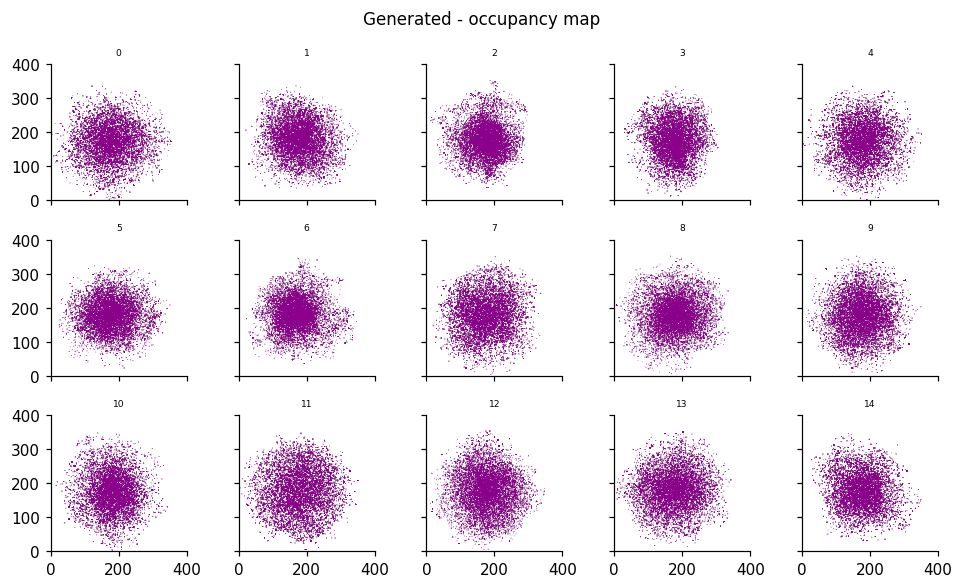

In [157]:
for df, title, n_ind in [(fish_df_long, 'Real', n_fish), (gen_fish_df_long, 'Generated', n_rollouts_frame)]:
    if df is None:
        print(f'{title}: no data'); continue

    ncols = 5
    nrows = int(np.ceil(n_ind / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * CELL_W, nrows * CELL_H), sharex=True, sharey=True)
    axes = axes.ravel()

    for f in range(n_ind):
        ax = axes[f]
        sub = df[df['fish_number'] == f]
        ax.scatter(sub['x'], sub['y'], color=COLORS[title], **DOT_FRAME)
        ax.set_title(str(f), fontsize=FS_TITLE)
        ax.set_xlim(0, 400); ax.set_ylim(0, 400)
        ax.set_aspect('equal')
    for ax in axes[n_ind:]:
        ax.axis('off')

    fig.suptitle(f'{title} - occupancy map', fontsize=FS_SUP)
    plt.tight_layout()
    #fig.savefig(PLOTS_DIR / f'occupancy_frame_{title}.png', dpi=150, bbox_inches='tight')
    plt.show()

#### 2. Position after stimulus appearance, by side & condition (frame-based -- full trajectory, not just bout onsets)

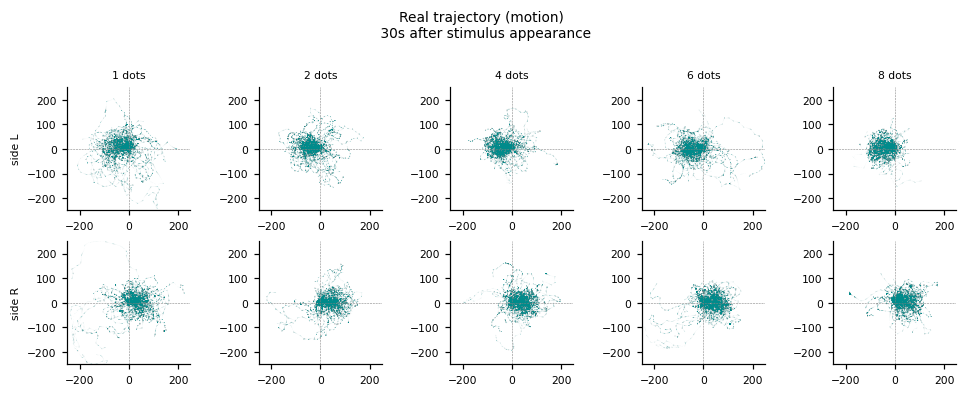

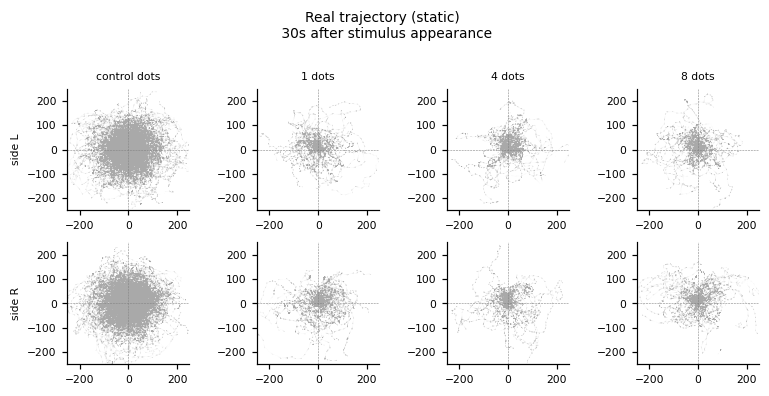

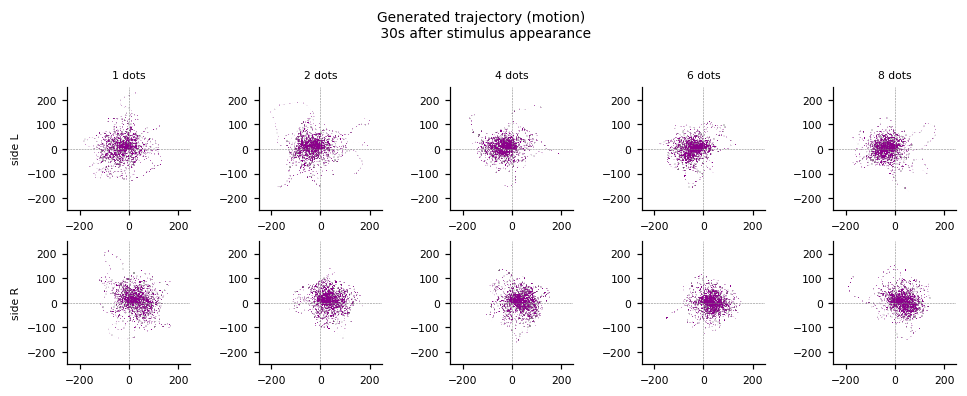

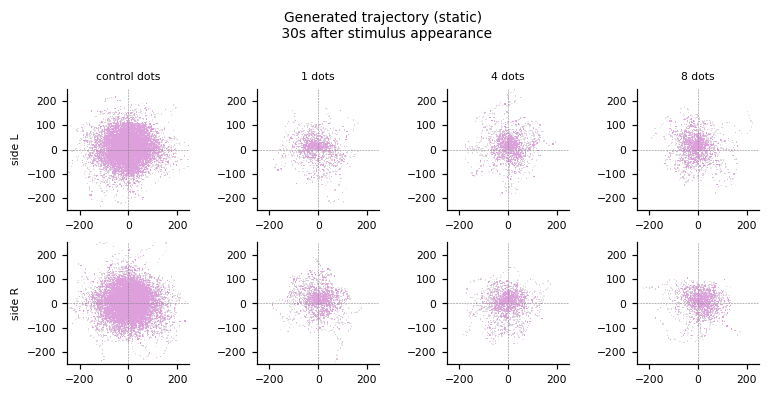

In [158]:
# Horizontal layout: columns = stimuli, rows = the 2 sides -- a transpose of the previous
# rows=stimuli/cols=side grid. Split into a motion figure and a static figure (instead of one
# combined STIMULI_ORDER figure) since all stimuli side-by-side made this too wide to read.
for df, title, n_ind in [(fish_df_long, 'Real', n_fish), (gen_fish_df_long, 'Generated', n_rollouts_frame)]:
    if df is None:
        print(f'{title}: no data'); continue

    SECONDS_AFTER_ONSET_LONG = 30
    for group_name, group_stimuli in [('motion', STIM_35), ('static', STIM_0)]:
        if not group_stimuli:
            continue
        # control (inter_stim_pause) is only a useful baseline next to the static group
        stimuli_with_control = group_stimuli if group_name == 'motion' else ['inter_stim_pause'] + group_stimuli
        fig_w = len(stimuli_with_control) * CELL_W
        fig, axes = plt.subplots(2, len(stimuli_with_control), figsize=(fig_w, 2 * CELL_H))

        for col, stim in enumerate(stimuli_with_control):
            for row, side in enumerate(['L', 'R']):
                ax = axes[row, col]
                sub = df[(df['stimulus'] == stim) & (df['stim_side'] == side)
                        & (df['frame_count_stimulus'] < SECONDS_AFTER_ONSET_LONG * framerate)]
                color = COND_COLORS[title]['motion' if is_motion(stim) else 'static']
                ax.scatter(sub['x_rot'], sub['y_rot'], color=color, s= 0.2, alpha= 0.05, edgecolor='none')
                if row == 0:
                    ax.set_title(f'{dots_label(stim)} dots', fontsize=7)
                if col == 0:
                    ax.set_ylabel(f'side {side}', fontsize=7)
                ax.axhline(0, color='grey', linewidth=0.35, linestyle='--')
                ax.axvline(0, color='grey', linewidth=0.35, linestyle='--')
                ax.tick_params(labelsize=7)
                ax.set_xlim(-250, 250); ax.set_ylim(-250, 250)
                ax.set_aspect('equal')
                ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

        fig.suptitle(f'{title} trajectory ({group_name}) \n {SECONDS_AFTER_ONSET_LONG}s after stimulus appearance',
                    fontsize=9)
        plt.tight_layout(rect=[0, 0, 1, 0.98])
        fig.savefig(PLOTS_DIR / f'cumtraj_afterstim_{title}_{group_name}.png', dpi=150, bbox_inches='tight')
        plt.show()

#### 3. Distance fish–dots over time

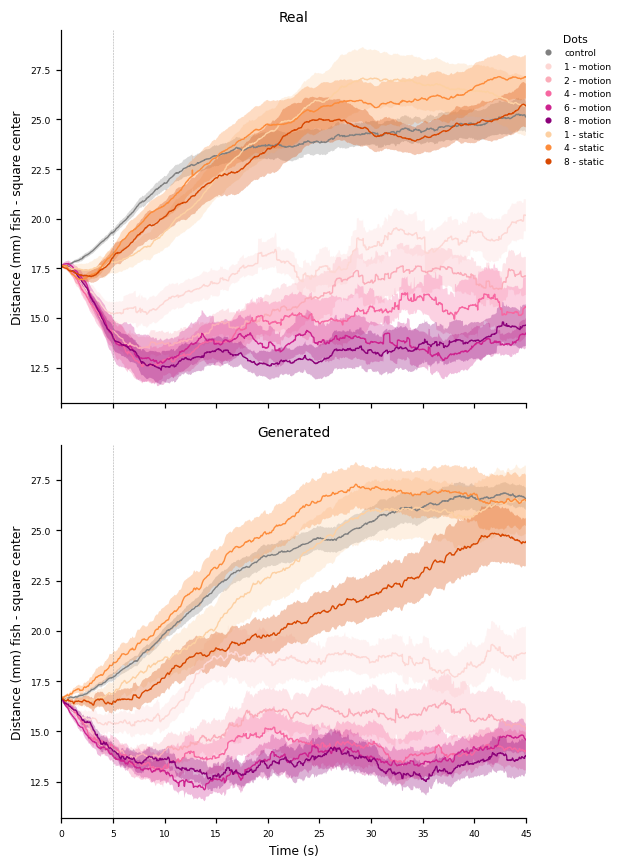

In [13]:
# One row per available dataset (Real skipped entirely -- not just left blank -- when there's
# no real data), 1 column.
datasets = [(df, title) for df, title in [(fish_df_long, 'Real'), (gen_fish_df_long, 'Generated')] if df is not None]
fig, axes = plt.subplots(len(datasets), 1, figsize=(5.8, 4 * len(datasets)), sharex=True)
axes = np.atleast_1d(axes)

TIME_AFTER_ONSET = 45
for row, (df, title) in enumerate(datasets):
    ax = axes[row]
    legend_handles = []
    for stim in ['inter_stim_pause'] + STIMULI_ORDER:
        color = color_map.get(stim, 'gray')
        legend_handles.append(Line2D([0], [0], marker='o', color=color, linestyle='None',
                                     markersize=3, label=auto_label(stim)))
        sub = df[(df['stimulus'] == stim) & (df['dots_out'] < 1)].copy()
        sub['dist_mm'] = sub['squareDist_rot'] / PX_TO_MM
        sub['time'] = sub['frame_count_stimulus'] / framerate
        per_fish = sub[sub['time'] <= TIME_AFTER_ONSET].groupby(['fish_number', 'time'])['dist_mm'].mean().reset_index()
        grouped = per_fish.groupby('time')['dist_mm']
        avg, sem = grouped.mean(), grouped.sem()
        ax.plot(avg.index, avg, color=color, linewidth=LW)
        ax.fill_between(avg.index, avg - sem, avg + sem, alpha=0.3, color=color, edgecolor='none')

    ax.axvline(5, linestyle='--', linewidth=.35, color='grey', alpha=0.7)
    ax.set_ylabel('Distance (mm) fish - square center', fontsize=8)
    ax.set_xlim(0, TIME_AFTER_ONSET)
    ax.set_title(title, fontsize=9)
    ax.tick_params(labelsize=FS_TICK)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    if row == 0:
        ax.legend(handles=legend_handles, title='Dots', loc='upper left', bbox_to_anchor=(1.02, 1),
                  borderaxespad=0., frameon=False, fontsize=FS_TICK, title_fontsize=7)

axes[-1].set_xlabel('Time (s)', fontsize=8)
plt.tight_layout()
#fig.savefig(PLOTS_DIR / 'dist_fish_dots.png', dpi=150, bbox_inches='tight')
plt.show()

#### 4. LR Time Ratio

In [16]:
lr_ratios_frame = {}
# Compute L/R time ratios per stimulus/side, averaged per fish across trials.
for df, title in [(fish_df_long, 'Real'), (gen_fish_df_long, 'Generated')]:
    lr_ratios_frame[title] = {}
    if df is None:
        continue
    for stim in ['inter_stim_pause'] + STIM_35 + STIM_0:
        for side in ['L', 'R']:
            sub = df[(df['stimulus'] == stim) & (df['stim_side'] == side)]
            left_time = sub[sub['x_rot'] < 0].groupby(['fish_number', 'trial_id']).size() / framerate
            right_time = sub[sub['x_rot'] > 0].groupby(['fish_number', 'trial_id']).size() / framerate
            left_avg, right_avg = left_time.groupby('fish_number').mean(), right_time.groupby('fish_number').mean()
            lr_ratios_frame[title][(stim, side)] = (left_avg - right_avg) / (left_avg + right_avg)

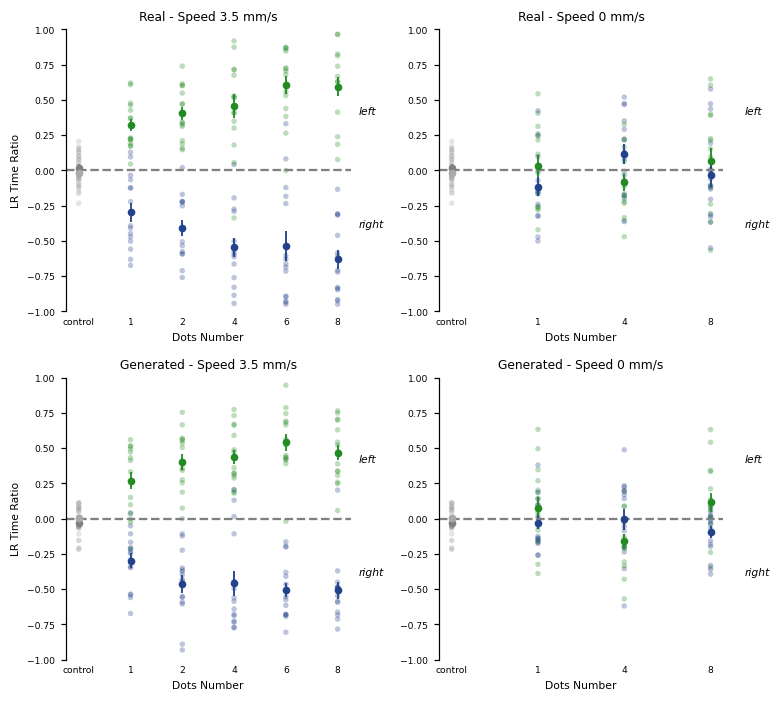

In [21]:
# One row per available dataset (Real skipped entirely, not left blank, when there's no real data)
groups = [g for g in (STIM_35, STIM_0) if g]
datasets = [title for title in ['Real', 'Generated'] if lr_ratios_frame.get(title)]
fig, axes = plt.subplots(len(datasets), len(groups), figsize=(len(groups) * CELL_W * 2, len(datasets) * CELL_H * 1.8), squeeze=False)

for row, title in enumerate(datasets):
    lr = lr_ratios_frame[title]
    for col, stimuli in enumerate(groups):
        ax = axes[row, col]
        speeds = sorted({parse_stim(s)[1] for s in stimuli})
        speed_title = f"Speed {', '.join(f'{s:g}' for s in speeds)} mm/s"
        stimuli_x = ['inter_stim_pause'] + stimuli
        x = np.arange(len(stimuli_x))
        for i, stim in enumerate(stimuli_x):
            for side in ['L', 'R']:
                base_color = '#228B22' if side == 'L' else '#22428B'
                if stim == 'inter_stim_pause':
                    base_color = 'gray' if side == 'L' else 'darkgray'
                y = lr.get((stim, side), pd.Series(dtype=float))
                ax.scatter([x[i]] * len(y), y, color=base_color, edgecolor='none', alpha=.3, s=13)
                sem = y.std(ddof=1) / np.sqrt(len(y)) if len(y) > 1 else 0
                ax.errorbar(x[i], y.mean(), yerr=sem, fmt='o', color=base_color, capsize=0,
                            elinewidth=1.2, markeredgecolor=base_color, markersize=4)
        ax.text(len(stimuli_x) - 0.6, 0.4, 'left', fontsize=FS_TICK + 1, fontstyle='italic', ha='left')
        ax.text(len(stimuli_x) - 0.6, -0.4, 'right', fontsize=FS_TICK + 1, fontstyle='italic', ha='left')
        ax.axhline(0, linestyle='--', color='gray')
        ax.set_xticks(x); ax.set_xticklabels([dots_label(s) for s in stimuli_x], ha='center', fontsize=FS_TICK)
        ax.tick_params(axis='x', length=0)
        ax.tick_params(axis='y', labelsize=FS_TICK)
        ax.set_ylim(-1, 1)
        if col == 0:
            ax.set_ylabel('LR Time Ratio', fontsize=7)
        ax.set_title(f'{title} - {speed_title}', fontsize=8)
        ax.set_xlabel('Dots Number', fontsize=7)
        ax.spines['bottom'].set_visible(False)

plt.tight_layout()
#fig.savefig(PLOTS_DIR / 'lr_ratio.png', dpi=150, bbox_inches='tight')
plt.show()